In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def create_weight_mask(template_shape, axis='horizontal', sigma_ratio=0.4):
    h, w = template_shape
    if axis == 'horizontal':
        x = np.linspace(-1, 1, w)
        weights = np.exp(-0.5 * (x / sigma_ratio)**2)
        mask = np.tile(weights, (h, 1))
    else:
        y = np.linspace(-1, 1, h)
        weights = np.exp(-0.5 * (y / sigma_ratio)**2)
        mask = np.tile(weights[:, None], (1, w))
    return mask.astype(np.float32)

import cv2
import numpy as np

def weighted_zncc(template, image, weight):
    T = template.astype(np.float32)
    I = image.astype(np.float32)
    W = weight.astype(np.float32)
    W_sum = np.sum(W)

    # Calcola mean_T e T_hat
    mean_T = np.sum(T * W) / W_sum
    T_hat = (T - mean_T) * W
    T_hat_sq_sum = np.sum(T_hat**2)

    # Patch sums via convoluzione: molto più veloce
    I_sum = cv2.filter2D(I, -1, W)
    I2_sum = cv2.filter2D(I**2, -1, W)
    IW_sum = cv2.filter2D(I, -1, T_hat)

    # mean_I e var_I per ogni finestra
    mean_I = I_sum / W_sum
    var_I = (I2_sum / W_sum) - mean_I**2
    var_I[var_I < 1e-10] = 1e-10  # evita instabilità numerica

    # Calcola ZNCC
    result = IW_sum / np.sqrt(T_hat_sq_sum * var_I)

    # Crop il bordo finale per matchTemplate-like result
    h, w = template.shape
    result = result[h - 1:I.shape[0], w - 1:I.shape[1]]

    # Estrai info come da cv2.minMaxLoc
    min_val = float(np.min(result))
    max_val = float(np.max(result))
    min_loc = tuple(np.unravel_index(np.argmin(result), result.shape)[::-1])  # (x, y)
    max_loc = tuple(np.unravel_index(np.argmax(result), result.shape)[::-1])  # (x, y)

    return result, min_val*0.01, max_val*0.01, min_loc, max_loc





In [3]:
def load_image(image_path, grayscale=False):
    if grayscale:
        return cv2.imread(image_path, cv2.IMREAD_GRAYSCALE) if image_path else print("Image path is empty.")
    else:
        img = cv2.imread(image_path)
        return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img is not None else print("Image not found or could not be loaded.")


def detect_and_describe_sift(image):
    
    sift = cv2.SIFT_create(
        contrastThreshold=0.03,
        edgeThreshold=5,
        sigma=1.0,
        nOctaveLayers=6,
    )

    kp, des = sift.detectAndCompute(image, None)

    return kp, des

# A function to find correspondences between two sets of keypoints and descriptors
'''CrossCheck e Lowe's ratio sono mutualmente esclusivi perchè CrossCheck forza ad usare bf.match
e quindi non permette di usare il KNN. Se si vuole usare il KNN, bisogna impostare cross_check=False.
In questo caso, si usa il KNN per trovare i due migliori match per ogni descrittore e poi si applica il test di Lowe's ratio.'''
def kp_matching_bf(des1, des2, norm_type=cv2.NORM_L2, cross_check=False, lowe_ratio=0.75):
    bf = cv2.BFMatcher(norm_type, crossCheck=cross_check)

    if cross_check:
        # Simple matching: only best match with crossCheck
        all_matches = bf.match(des1, des2)
        good_matches = sorted(all_matches, key=lambda x: x.distance)
    else:
        # KNN matching + Lowe's ratio test
        if len(des1) <= 1 or len(des2) <= 1:
            return [], []
        matches = bf.knnMatch(des1, des2, k=2)
        if matches is None or len(matches) == 0:
            return [], []
        all_matches = [] 
        good_matches = []
        for m, n in matches:
            all_matches.append(m)
            if m.distance < lowe_ratio * n.distance:
                good_matches.append(m)


    return all_matches, good_matches


# Find model object within scene image
def find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0):
    if len(good_matches) < min_match_count:
        return None, None

    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

    M, mask = cv2.findHomography(src_pts, dst_pts, method, ransacReprojThreshold)

    return M, mask


def perform_template_matching_rot_scale(scene_img, template_img, des_model, hysteresys_th, method=cv2.TM_CCOEFF_NORMED, angles=range(-6, 7, 2), scales=np.linspace(0.95, 1.05, 5)):

    low_threshold, high_threshold = hysteresys_th

    # Se le immagini sono a colori, convertile in scala di grigi
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = -np.inf
    top_left_best = None
    best_w = None
    best_h = None

    for scale in scales:
        # Ridimensiona il template
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            # Ruota il template scalato
            rot_mat = cv2.getRotationMatrix2D((w0 / 2, h0 / 2), angle, 1.0)
            rotated_template = cv2.warpAffine(scaled_template, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            # Salta se il template diventa più grande della scena
            if rotated_template.shape[0] > scene_gray.shape[0] or rotated_template.shape[1] > scene_gray.shape[1]:
                continue

            # Esegui il template matching
            #weighted_mask = create_weight_mask(rotated_template.shape, axis='horizontal', sigma_ratio=0.4)
            #result, min_val, max_val, min_loc, max_loc = weighted_zncc(rotated_template, scene_gray, weighted_mask)
            result = cv2.matchTemplate(scene_gray, rotated_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            if method in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
                match_val = -min_val  # Per coerenza, invertiamo SQDIFF
                top_left = min_loc
            else:
                match_val = max_val
                top_left = max_loc

            if match_val > best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0

    # Compute corners of the current box
    bottom_right_best = (top_left_best[0] + best_w, top_left_best[1] + best_h)

    corners = np.array([
        [list(top_left_best)],
        [list((top_left_best[0], bottom_right_best[1]))],
        [list(bottom_right_best)],
        [list((bottom_right_best[0], top_left_best[1]))]
    ])
    print(f"Best val: {best_match_val}")
    matched = False
    detected = False
    if best_match_val >= high_threshold:
        matched = True
        detected = True
        print("Match found above highthreshold.")
    elif best_match_val < low_threshold:
        matched = False
        detected = False
        print(f"Value {best_match_val} below low threshold {low_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        # Match descriptors of the box with the model
        all_matches, good_matches = kp_matching_bf(des_model, des_box, lowe_ratio=0.8)

        mul_factor = (1-best_match_val)+low_threshold
        min_matches = int(0.125 * len(des_model) * mul_factor)

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. Match value: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. No match found. Match value: {best_match_val}.")

    if matched: # togliere matched  e fare il controllo corners ==  None
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected  # Nessun match sopra la soglia


def extract_template_from_corners(image, corners):
    # Assicura che corners sia nella forma corretta
    corners = corners.reshape(-1, 2).astype(np.int32)

    # Trova i limiti del rettangolo che contiene tutti i corner
    x_min = np.min(corners[:, 0])
    y_min = np.min(corners[:, 1])
    x_max = np.max(corners[:, 0])
    y_max = np.max(corners[:, 1])

    # Ritaglia la regione rettangolare direttamente dall'immagine
    cropped_region = image[y_min:y_max, x_min:x_max]

    return cropped_region


def show_keypoints(image, keypoints):
    img_with_keypoints = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    plt.figure(figsize=(10, 10))
    plt.imshow(img_with_keypoints)
    plt.axis('off')
    plt.show()

def show_correspondences(image1, image2, kp1, kp2, matches):
    img_matches = cv2.drawMatches(image1, kp1, image2, kp2, matches, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(15, 10))
    plt.imshow(img_matches)
    plt.axis('off')
    plt.show()

# Function to draw the bounding box around the detected model in the scene
def draw_bounding_box(img_scene, img_model, M):
    # Corners of the model image
    h, w = img_model.shape[:2]
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Project the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Draw the bounding box
    img_scene_with_box = cv2.polylines(img_scene, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

    return np.int32(dst), img_scene_with_box

def draw_matched_rectangle(image,corners):

    image_with_rectangle = image.copy()
    cv2.polylines(image_with_rectangle, [corners], True, (0, 255, 0), 2)
    return image_with_rectangle

'''# A function to remove the detected object from the scene image
def remove_object_from_scene(img_scene, corners):
    # Create a mask for the detected object
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [corners], (255))

    # Invert the mask to keep the background
    mask_inv = cv2.bitwise_not(mask)

    # Remove the object from the scene image
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object'''


def remove_object_from_scene(img_scene, corners, shrink_ratio=0.75):

    corners_reshaped = corners.reshape(-1, 2)
    # Calcola bounding box axis-aligned
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    # Centroide geometrico
    center = np.array([np.mean(x_coords), np.mean(y_coords)])
    
    # Determina asse corto (0 = x, 1 = y)
    if width < height:
        shrink_axis = 0  # shrink solo lungo X
    else:
        shrink_axis = 1  # shrink solo lungo Y

    # Applica shrink solo lungo asse corto
    scaled_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        scaled_corners.append(scaled_pt)

    scaled_corners = np.array(scaled_corners, dtype=np.int32)

    # Crea maschera e rimuove l'oggetto
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [scaled_corners], 255)
    mask_inv = cv2.bitwise_not(mask)
    img_scene_no_object = cv2.bitwise_and(img_scene, img_scene, mask=mask_inv)

    return img_scene_no_object

def warp_to_rect(image, corners):
    # Assicura che corners sia (4, 2)
    corners = corners.reshape(4, 2).astype(np.float32)

    # Ordina i punti in ordine: top-left, top-right, bottom-right, bottom-left
    def order_points(pts):
        rect = np.zeros((4, 2), dtype="float32")
        s = pts.sum(axis=1)
        rect[0] = pts[np.argmin(s)]      # Top-left
        rect[2] = pts[np.argmax(s)]      # Bottom-right

        diff = np.diff(pts, axis=1)
        rect[1] = pts[np.argmin(diff)]   # Top-right
        rect[3] = pts[np.argmax(diff)]   # Bottom-left
        return rect

    rect = order_points(corners)
    (tl, tr, br, bl) = rect

    # Calcola la larghezza massima e altezza massima del nuovo rettangolo
    widthA = np.linalg.norm(br - bl)
    widthB = np.linalg.norm(tr - tl)
    maxWidth = int(max(widthA, widthB))

    heightA = np.linalg.norm(tr - br)
    heightB = np.linalg.norm(tl - bl)
    maxHeight = int(max(heightA, heightB))

    # Definisci i punti della destinazione (rettangolo perfetto)
    dst = np.array([
        [0, 0],
        [maxWidth - 1, 0],
        [maxWidth - 1, maxHeight - 1],
        [0, maxHeight - 1]
    ], dtype="float32")

    # Calcola la trasformazione prospettica e applicala
    M = cv2.getPerspectiveTransform(rect, dst)
    warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

    return warped


def remove_object_from_scene2(img_scene, corners, shrink_ratio=0.65):

    corners_reshaped = corners.reshape(-1, 2)
    x_coords = corners_reshaped[:, 0]
    y_coords = corners_reshaped[:, 1]
    
    width = x_coords.max() - x_coords.min()
    height = y_coords.max() - y_coords.min()
    
    center = np.array([np.mean(x_coords), np.mean(y_coords)])
    
    shrink_axis = 0 if width < height else 1

    # Ridimensiona il poligono verso il centroide
    scaled_corners = []
    for pt in corners_reshaped:
        vec = pt - center
        vec[shrink_axis] *= shrink_ratio
        scaled_pt = center + vec
        scaled_corners.append(scaled_pt)

    scaled_corners = np.array(scaled_corners, dtype=np.int32)

    # Crea maschera della regione da "rimuovere"
    mask = np.zeros(img_scene.shape[:2], dtype=np.uint8)
    cv2.fillPoly(mask, [scaled_corners], 255)

    # Crea rumore casuale della stessa dimensione dell'immagine
    noise = np.random.randint(0, 256, img_scene.shape, dtype=np.uint8)

    # Applica la maschera per inserire il rumore solo nell'area target
    img_result = img_scene.copy()
    img_result[mask == 255] = noise[mask == 255]

    return img_result



In [4]:
def perform_template_matching_rot_scale_ssd(scene_img, template_img, des_model, hysteresys_th,
                                            method=cv2.TM_SQDIFF_NORMED,
                                            angles=range(-6, 7, 2),
                                            scales=np.linspace(0.95, 1.05, 5)):
    low_threshold, high_threshold = hysteresys_th

    # Converti in grayscale se necessario
    if len(scene_img.shape) >= 3:
        scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    else:
        scene_gray = scene_img.copy()

    if len(template_img.shape) == 3:
        template_orig_gray = cv2.cvtColor(template_img, cv2.COLOR_BGR2GRAY)
    else:
        template_orig_gray = template_img.copy()

    best_match_val = np.inf  # perché cerchiamo il minimo in SSD
    top_left_best = None
    best_w = None
    best_h = None

    for scale in scales:
        scaled_template = cv2.resize(template_orig_gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_LINEAR)
        h0, w0 = scaled_template.shape[:2]

        for angle in angles:
            rot_mat = cv2.getRotationMatrix2D((w0 / 2, h0 / 2), angle, 1.0)
            rotated_template = cv2.warpAffine(scaled_template, rot_mat, (w0, h0), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

            if rotated_template.shape[0] > scene_gray.shape[0] or rotated_template.shape[1] > scene_gray.shape[1]:
                continue

            result = cv2.matchTemplate(scene_gray, rotated_template, method)
            min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

            # SSD: valori minori sono migliori
            match_val = min_val
            top_left = min_loc

            '''if match_val < best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0'''
#-------         
            if match_val < best_match_val:
                best_match_val = match_val
                top_left_best = top_left
                best_w = w0
                best_h = h0
                best_angle = angle
                best_scale = scale
                best_rot_mat = rot_mat.copy()  # salva matrice di rotazione
#-------


    # Se nessun match è stato trovato
    if top_left_best is None:
        return None, best_match_val, False

    # Calcolo dei corner del rettangolo trovato
    '''bottom_right_best = (top_left_best[0] + best_w, top_left_best[1] + best_h)
    corners = np.array([
        [list(top_left_best)],
        [list((top_left_best[0], bottom_right_best[1]))],
        [list(bottom_right_best)],
        [list((bottom_right_best[0], top_left_best[1]))]
    ])'''
#-------
    print(best_angle)
    # Costruisci i 4 corner del template in coordinate locali (0,0)–(w,h)
    local_corners = np.array([
        [0, 0],
        [0, best_h],
        [best_w, best_h],
        [best_w, 0]
    ], dtype=np.float32)

    # Applica rotazione (matrice affine) al template
    rotated_corners = cv2.transform(np.array([local_corners]), best_rot_mat)[0]

    # Trasla nella scena, usando top_left_best
    corners = rotated_corners + np.array(top_left_best, dtype=np.float32)
    corners = corners.reshape((4, 2)).astype(int)
#-------

    print(f"Best SSD val: {best_match_val}")
    matched = False
    detected = False

    if best_match_val <= low_threshold:  # SSD: match buoni = valori piccoli
        matched = True
        detected = True
        print("Match found below low threshold (SSD).")
    elif best_match_val > high_threshold:
        matched = False
        detected = False
        print(f"Value {best_match_val} above high threshold {high_threshold}. No match found.")
    else:
        matched = True
        current_box = extract_template_from_corners(scene_img, corners)
        kp_box, des_box = detect_and_describe_sift(current_box)
        if kp_box is None or des_box is None:
            return corners, best_match_val, False

        all_matches, good_matches = kp_matching_bf(des_model, des_box, lowe_ratio=0.8)

        mul_factor = best_match_val + low_threshold  # SSD: peggiore = valore alto
        #min_matches = int(0.125 * len(des_model) * mul_factor)
        min_matches = int(0.12 * len(des_model))

        if len(good_matches) >= min_matches:
            detected = True
            print(f"New match found with {len(good_matches)}/{min_matches} good matches. SSD: {best_match_val}.")
        else:
            detected = False
            print(f"Not enough matches: {len(good_matches)}/{min_matches}. SSD: {best_match_val}.")

    if matched:
        return corners, best_match_val, detected
    else:
        return None, best_match_val, detected


In [5]:

def main(model_path, scene_path, 
         grayscale=False,
         min_match_pct=0.1,
         cross_check=False, 
         lowe_ratio=0.8, 
         hysteresys_th=(0.45, 0.8),
         method=cv2.RANSAC, 
         ransacReprojThreshold=5.0, 
         similarity_measure=cv2.TM_CCOEFF_NORMED):

    detections = 0

    model_img = load_image(model_path, grayscale=grayscale)
    scene_img = load_image(scene_path, grayscale=grayscale)

    scene = scene_img.copy()

    # Detect keypoints and descriptors
    kp_model, des_model = detect_and_describe_sift(model_img)
    kp_scene, des_scene = detect_and_describe_sift(scene_img)

    if kp_model is None or kp_scene is None:
        print("No keypoints or descriptors found in the model or scene image.")
        return

    # Match keypoints
    all_matches, good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, cross_check=cross_check, lowe_ratio=lowe_ratio)
    
    # Find homography
    min_match_count = int(min_match_pct * len(kp_model))
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count, good_matches)
    if M is None:
        print("Homography could not be computed. No instances detected.")
        return
    else:
        print(f"Homography computed successfully")
    
    detections += 1

    # Draw bounding box around the detected model in the scene
    corners, img_scene_with_box = draw_bounding_box(scene, model_img, M)

    # Compute ROI from the corners
    # roi_scene = compute_roi(scene_img, corners)

    # Extract the template to permit template matching
    #template = extract_template_from_corners(scene_img, corners)
    template = warp_to_rect(scene_img, corners)
    plt.imshow(template)
    plt.show()
    i=0
    while i<20:
        # Mask the object detected
        scene_img = remove_object_from_scene2(scene_img, corners)
        # plt.imshow(scene_img)
        # plt.show()

        # Perform template matching in the ROI
        #corners, match_val, detected = perform_template_matching_rot_scale(scene_img, template, des_model, hysteresys_th, method=similarity_measure)
        corners, match_val, detected = perform_template_matching_rot_scale_ssd(scene_img, template, des_model, hysteresys_th, method=cv2.TM_SQDIFF_NORMED)
        print(corners)
        if corners is None:
            print(f"No match found during template matching on instance {detections+1}. Matching value: {match_val}/{hysteresys_th[0]}.")
            break

        if detected:
            detections += 1
            scene = draw_matched_rectangle(scene, corners)

        i += 1

    print(f"Total instances detected: {detections}")
    if detections > 0:
        plt.imshow(scene)
        plt.show()




Homography computed successfully


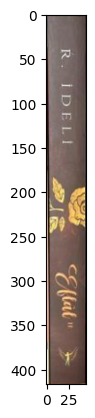

0
Best SSD val: 0.10215630382299423
New match found with 157/116 good matches. SSD: 0.10215630382299423.
[[306 139]
 [306 577]
 [353 577]
 [353 139]]
0
Best SSD val: 0.1567709892988205
New match found with 119/116 good matches. SSD: 0.1567709892988205.
[[471 133]
 [471 571]
 [518 571]
 [518 133]]
0
Best SSD val: 0.1767210066318512
Not enough matches: 15/116. SSD: 0.1767210066318512.
[[257 145]
 [257 572]
 [303 572]
 [303 145]]
0
Best SSD val: 0.17923516035079956
Not enough matches: 20/116. SSD: 0.17923516035079956.
[[192 131]
 [192 527]
 [235 527]
 [235 131]]
0
Best SSD val: 0.18126873672008514
Not enough matches: 20/116. SSD: 0.18126873672008514.
[[257 141]
 [257 568]
 [303 568]
 [303 141]]
0
Best SSD val: 0.1809004545211792
Not enough matches: 17/116. SSD: 0.1809004545211792.
[[257 141]
 [257 568]
 [303 568]
 [303 141]]
0
Best SSD val: 0.18006902933120728
Not enough matches: 18/116. SSD: 0.18006902933120728.
[[257 141]
 [257 568]
 [303 568]
 [303 141]]
0
Best SSD val: 0.1785529553890

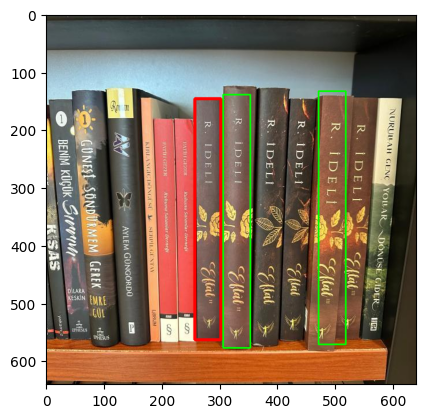

In [6]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
min_match_pct = 0.075
hyst_th = (0.03, 0.27)

scene_path = f'./dataset/scenes/scene_27.jpg'
model_path = f'./dataset/models/model_2.png'
          
main(model_path, scene_path, 
    grayscale=grayscale, 
    hysteresys_th=hyst_th, 
    min_match_pct=min_match_pct,
    cross_check=crosscheck, 
    lowe_ratio=lowe_ratio, 
    method=cv2.RANSAC, 
    ransacReprojThreshold=5.0, 
    similarity_measure=cv2.TM_CCOEFF_NORMED)

In [ ]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
min_match_pct = 0.06
hyst_th = (0.55, 0.80)

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"-------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          main(model_path, scene_path, 
               grayscale=grayscale, 
               hysteresys_th=hyst_th, 
               min_match_pct=min_match_pct,
               cross_check=crosscheck, 
               lowe_ratio=lowe_ratio, 
               method=cv2.RANSAC, 
               ransacReprojThreshold=5.0, 
               similarity_measure=cv2.TM_CCOEFF_NORMED)

--------------------------------- Processing scene 0 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

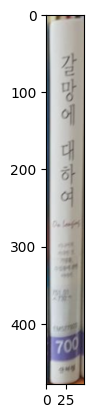

Best SSD val: 0.04869246855378151
New match found with 181/55 good matches. SSD: 0.04869246855378151.
Best SSD val: 0.0664142519235611
Not enough matches: 22/55. SSD: 0.0664142519235611.
Best SSD val: 0.08619450032711029
Not enough matches: 18/55. SSD: 0.08619450032711029.
Best SSD val: 0.10944658517837524
Not enough matches: 20/55. SSD: 0.10944658517837524.
Best SSD val: 0.10814115405082703
Not enough matches: 16/55. SSD: 0.10814115405082703.
Best SSD val: 0.13896234333515167
Not enough matches: 17/55. SSD: 0.13896234333515167.
Best SSD val: 0.16851365566253662
Not enough matches: 2/55. SSD: 0.16851365566253662.
Best SSD val: 0.17390784621238708
Not enough matches: 27/55. SSD: 0.17390784621238708.
Best SSD val: 0.1904224008321762
Not enough matches: 4/55. SSD: 0.1904224008321762.
Best SSD val: 0.19043126702308655
Not enough matches: 3/55. SSD: 0.19043126702308655.
Best SSD val: 0.19071835279464722
Not enough matches: 4/55. SSD: 0.19071835279464722.
Best SSD val: 0.2004326730966568
Not

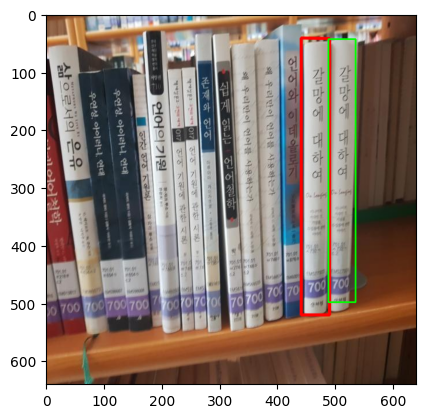

-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 2 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be com

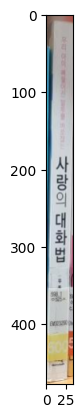

Best SSD val: 0.06391680240631104
Not enough matches: 45/84. SSD: 0.06391680240631104.
Best SSD val: 0.07526830583810806
Not enough matches: 30/84. SSD: 0.07526830583810806.
Best SSD val: 0.08905508369207382
Not enough matches: 22/84. SSD: 0.08905508369207382.
Best SSD val: 0.12349850684404373
Not enough matches: 34/84. SSD: 0.12349850684404373.
Best SSD val: 0.12461090832948685
Not enough matches: 29/84. SSD: 0.12461090832948685.
Best SSD val: 0.13069552183151245
Not enough matches: 31/84. SSD: 0.13069552183151245.
Best SSD val: 0.14584343135356903
Not enough matches: 23/84. SSD: 0.14584343135356903.
Best SSD val: 0.1463254988193512
Not enough matches: 27/84. SSD: 0.1463254988193512.
Best SSD val: 0.14752233028411865
Not enough matches: 27/84. SSD: 0.14752233028411865.
Best SSD val: 0.15918979048728943
Not enough matches: 21/84. SSD: 0.15918979048728943.
Best SSD val: 0.1598309725522995
Not enough matches: 18/84. SSD: 0.1598309725522995.
Best SSD val: 0.1758200228214264
Not enough mat

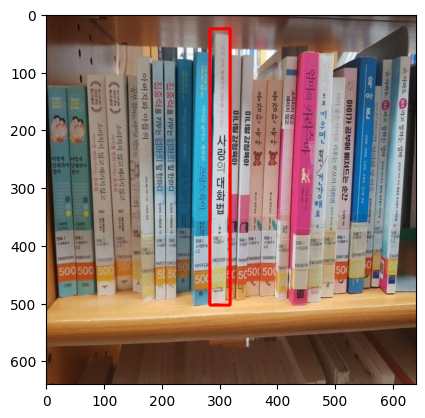

-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 3 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be co

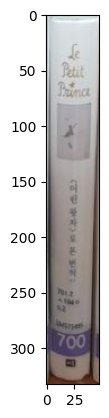

Best SSD val: 0.02760566957294941
Match found below low threshold (SSD).
Best SSD val: 0.05355806276202202
Not enough matches: 17/93. SSD: 0.05355806276202202.
Best SSD val: 0.054657936096191406
Not enough matches: 30/93. SSD: 0.054657936096191406.
Best SSD val: 0.05504830926656723
Not enough matches: 12/93. SSD: 0.05504830926656723.
Best SSD val: 0.0685080885887146
Not enough matches: 22/93. SSD: 0.0685080885887146.
Best SSD val: 0.08125744014978409
Not enough matches: 24/93. SSD: 0.08125744014978409.
Best SSD val: 0.09683243185281754
Not enough matches: 16/93. SSD: 0.09683243185281754.
Best SSD val: 0.10552307963371277
Not enough matches: 22/93. SSD: 0.10552307963371277.
Best SSD val: 0.11742062121629715
Not enough matches: 5/93. SSD: 0.11742062121629715.
Best SSD val: 0.11776558309793472
Not enough matches: 9/93. SSD: 0.11776558309793472.
Best SSD val: 0.12315861880779266
Not enough matches: 17/93. SSD: 0.12315861880779266.
Best SSD val: 0.13631589710712433
Not enough matches: 8/93.

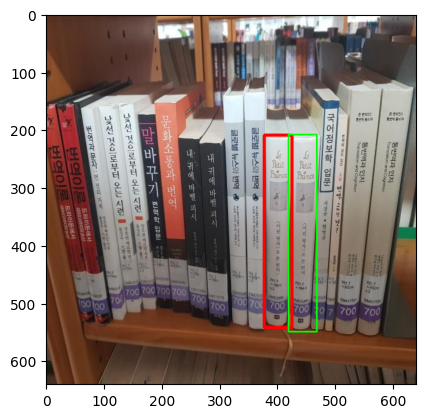

-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 4 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be c

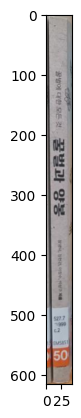

Best SSD val: 0.06413033604621887
New match found with 303/153 good matches. SSD: 0.06413033604621887.
Best SSD val: 0.13497120141983032
Not enough matches: 43/153. SSD: 0.13497120141983032.
Best SSD val: 0.14239105582237244
Not enough matches: 21/153. SSD: 0.14239105582237244.
Best SSD val: 0.14405028522014618
Not enough matches: 12/153. SSD: 0.14405028522014618.
Best SSD val: 0.14447171986103058
Not enough matches: 14/153. SSD: 0.14447171986103058.
Best SSD val: 0.14550049602985382
Not enough matches: 14/153. SSD: 0.14550049602985382.
Best SSD val: 0.1468908190727234
Not enough matches: 10/153. SSD: 0.1468908190727234.
Best SSD val: 0.14786015450954437
Not enough matches: 14/153. SSD: 0.14786015450954437.
Best SSD val: 0.14379259943962097
Not enough matches: 11/153. SSD: 0.14379259943962097.
Best SSD val: 0.1471603661775589
Not enough matches: 14/153. SSD: 0.1471603661775589.
Best SSD val: 0.1453724503517151
Not enough matches: 18/153. SSD: 0.1453724503517151.
Best SSD val: 0.1474212

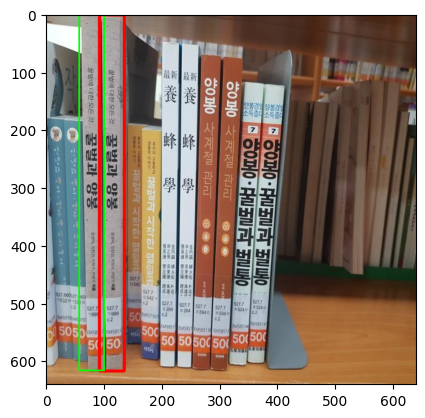

-------- Processing model 15 --------
Homography computed successfully


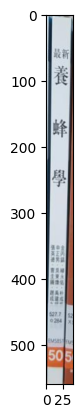

Best SSD val: 0.09957849234342575
New match found with 367/155 good matches. SSD: 0.09957849234342575.
Best SSD val: 0.19060266017913818
Not enough matches: 67/155. SSD: 0.19060266017913818.
Best SSD val: 0.19897931814193726
Not enough matches: 57/155. SSD: 0.19897931814193726.
Best SSD val: 0.24160902202129364
Not enough matches: 45/155. SSD: 0.24160902202129364.
Best SSD val: 0.2519168257713318
Not enough matches: 42/155. SSD: 0.2519168257713318.
Best SSD val: 0.26886501908302307
Not enough matches: 26/155. SSD: 0.26886501908302307.
Best SSD val: 0.27139565348625183
Value 0.27139565348625183 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.27139565348625183/0.03.
Total instances detected: 2


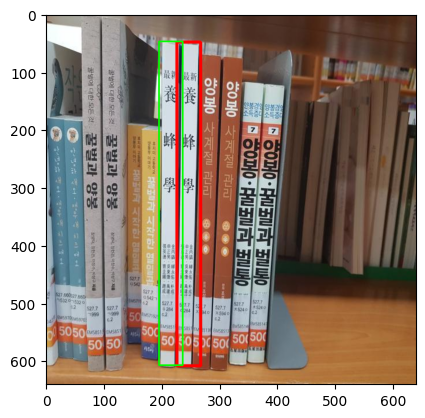

-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 5 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be 

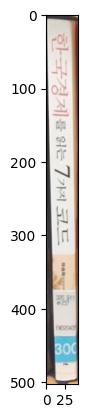

Best SSD val: 0.14775748550891876
Not enough matches: 45/119. SSD: 0.14775748550891876.
Best SSD val: 0.1577475219964981
Not enough matches: 57/119. SSD: 0.1577475219964981.
Best SSD val: 0.19704237580299377
Not enough matches: 53/119. SSD: 0.19704237580299377.
Best SSD val: 0.21750792860984802
Not enough matches: 36/119. SSD: 0.21750792860984802.
Best SSD val: 0.2313682585954666
Not enough matches: 36/119. SSD: 0.2313682585954666.
Best SSD val: 0.23277591168880463
Not enough matches: 55/119. SSD: 0.23277591168880463.
Best SSD val: 0.26007163524627686
Not enough matches: 25/119. SSD: 0.26007163524627686.
Best SSD val: 0.2747485041618347
Value 0.2747485041618347 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.2747485041618347/0.03.
Total instances detected: 1


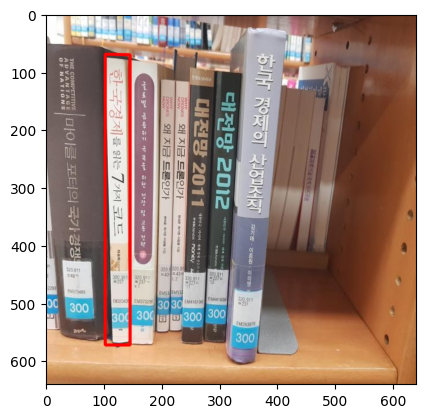

-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 6 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not b

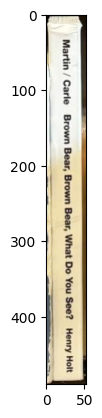

Best SSD val: 0.20123746991157532
Not enough matches: 37/130. SSD: 0.20123746991157532.
Best SSD val: 0.20488564670085907
Not enough matches: 63/130. SSD: 0.20488564670085907.
Best SSD val: 0.20608310401439667
Not enough matches: 82/130. SSD: 0.20608310401439667.
Best SSD val: 0.21208634972572327
Not enough matches: 75/130. SSD: 0.21208634972572327.
Best SSD val: 0.2825682461261749
Value 0.2825682461261749 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.2825682461261749/0.03.
Total instances detected: 1


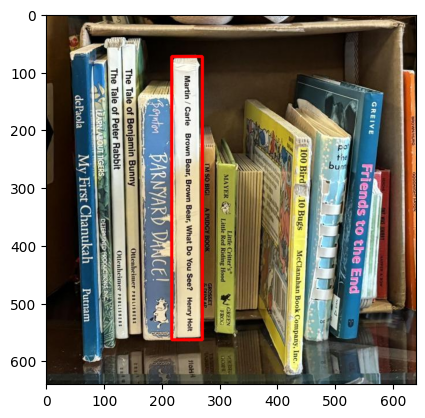

--------------------------------- Processing scene 7 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be comput

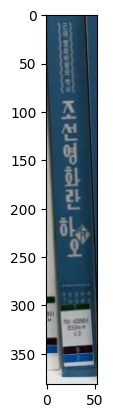

Best SSD val: 0.15489141643047333
New match found with 287/98 good matches. SSD: 0.15489141643047333.
Best SSD val: 0.27782702445983887
Value 0.27782702445983887 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.27782702445983887/0.03.
Total instances detected: 2


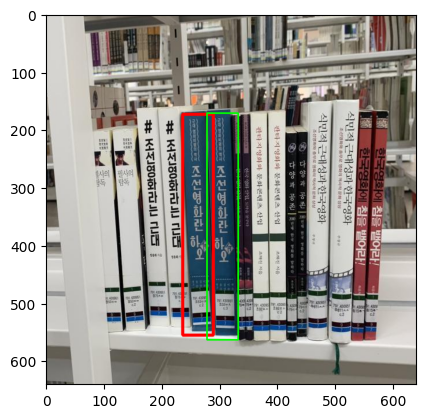

-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 8 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be compu

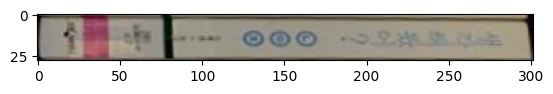

Best SSD val: 0.05312933772802353
Not enough matches: 13/59. SSD: 0.05312933772802353.
Best SSD val: 0.05390080064535141
Not enough matches: 25/59. SSD: 0.05390080064535141.
Best SSD val: 0.05402091145515442
Not enough matches: 10/59. SSD: 0.05402091145515442.
Best SSD val: 0.05741577968001366
New match found with 100/59 good matches. SSD: 0.05741577968001366.
Best SSD val: 0.058788884431123734
Not enough matches: 12/59. SSD: 0.058788884431123734.
Best SSD val: 0.06441241502761841
New match found with 75/59 good matches. SSD: 0.06441241502761841.
Best SSD val: 0.0660545751452446
Not enough matches: 26/59. SSD: 0.0660545751452446.
Best SSD val: 0.07272343337535858
New match found with 70/59 good matches. SSD: 0.07272343337535858.
Best SSD val: 0.07389387488365173
Not enough matches: 18/59. SSD: 0.07389387488365173.
Best SSD val: 0.07573583722114563
Not enough matches: 17/59. SSD: 0.07573583722114563.
Best SSD val: 0.07892841845750809
Not enough matches: 14/59. SSD: 0.07892841845750809.


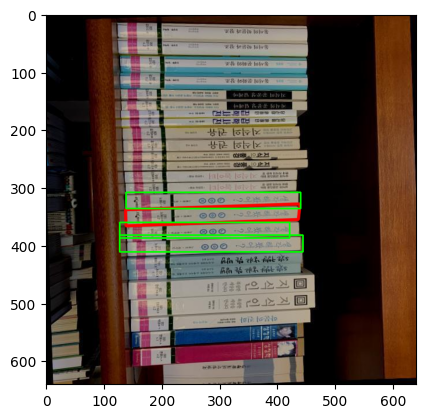

-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 10 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be com

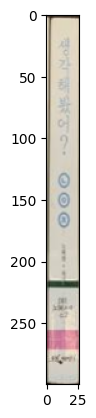

Best SSD val: 0.021996641531586647
Match found below low threshold (SSD).
Best SSD val: 0.026060957461595535
Match found below low threshold (SSD).
Best SSD val: 0.038316674530506134
New match found with 74/59 good matches. SSD: 0.038316674530506134.
Best SSD val: 0.04246162250638008
Not enough matches: 28/59. SSD: 0.04246162250638008.
Best SSD val: 0.044326577335596085
Not enough matches: 10/59. SSD: 0.044326577335596085.
Best SSD val: 0.04486369714140892
Not enough matches: 19/59. SSD: 0.04486369714140892.
Best SSD val: 0.046094752848148346
Not enough matches: 3/59. SSD: 0.046094752848148346.
Best SSD val: 0.04832177236676216
Not enough matches: 23/59. SSD: 0.04832177236676216.
Best SSD val: 0.05092582479119301
Not enough matches: 20/59. SSD: 0.05092582479119301.
Best SSD val: 0.05144913122057915
Not enough matches: 14/59. SSD: 0.05144913122057915.
Best SSD val: 0.05161861702799797
Not enough matches: 16/59. SSD: 0.05161861702799797.
Best SSD val: 0.0528210885822773
Not enough matche

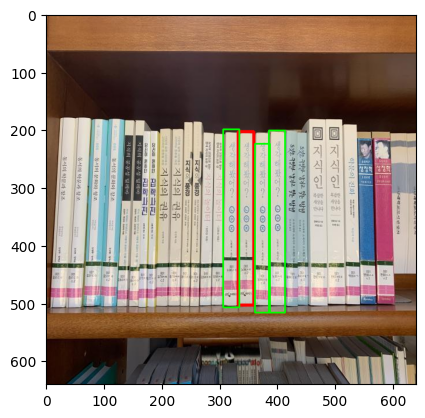

-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 11 ---------------------------------
-------- Processing model 0 --------
Homography could not be computed. No instances detected.
-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be com

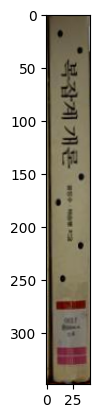

Best SSD val: 0.10587775707244873
Not enough matches: 29/90. SSD: 0.10587775707244873.
Best SSD val: 0.11560378223657608
New match found with 92/90 good matches. SSD: 0.11560378223657608.
Best SSD val: 0.1554100066423416
Not enough matches: 39/90. SSD: 0.1554100066423416.
Best SSD val: 0.15743012726306915
Not enough matches: 27/90. SSD: 0.15743012726306915.
Best SSD val: 0.18455514311790466
Not enough matches: 19/90. SSD: 0.18455514311790466.
Best SSD val: 0.18754373490810394
Not enough matches: 8/90. SSD: 0.18754373490810394.
Best SSD val: 0.19561773538589478
Not enough matches: 19/90. SSD: 0.19561773538589478.
Best SSD val: 0.2003515362739563
Not enough matches: 23/90. SSD: 0.2003515362739563.
Best SSD val: 0.22006340324878693
Not enough matches: 9/90. SSD: 0.22006340324878693.
Best SSD val: 0.21700190007686615
Not enough matches: 10/90. SSD: 0.21700190007686615.
Best SSD val: 0.2196226269006729
Not enough matches: 15/90. SSD: 0.2196226269006729.
Best SSD val: 0.22032158076763153
Not

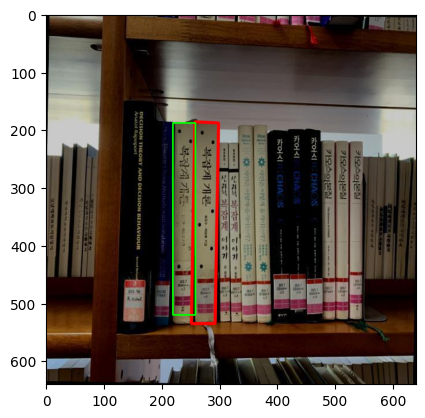

-------- Processing model 12 --------
Homography computed successfully


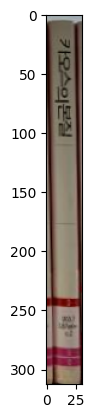

Best SSD val: 0.11284390836954117
Not enough matches: 19/47. SSD: 0.11284390836954117.
Best SSD val: 0.13089781999588013
New match found with 70/47 good matches. SSD: 0.13089781999588013.
Best SSD val: 0.1418643444776535
Not enough matches: 24/47. SSD: 0.1418643444776535.
Best SSD val: 0.1479717344045639
Not enough matches: 24/47. SSD: 0.1479717344045639.
Best SSD val: 0.16750341653823853
Not enough matches: 18/47. SSD: 0.16750341653823853.
Best SSD val: 0.18077903985977173
Not enough matches: 15/47. SSD: 0.18077903985977173.
Best SSD val: 0.1977618783712387
New match found with 72/47 good matches. SSD: 0.1977618783712387.
Best SSD val: 0.21161259710788727
Not enough matches: 8/47. SSD: 0.21161259710788727.
Best SSD val: 0.22193416953086853
Not enough matches: 5/47. SSD: 0.22193416953086853.
Best SSD val: 0.2251797616481781
Not enough matches: 5/47. SSD: 0.2251797616481781.
Best SSD val: 0.24309563636779785
Not enough matches: 3/47. SSD: 0.24309563636779785.
Best SSD val: 0.24387894570

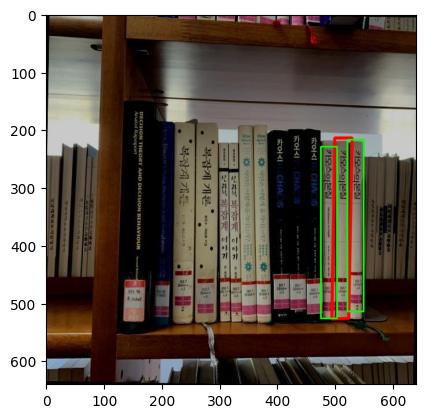

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 16 ---------------------------------
-------- Processing model 0 --------
Homography could not

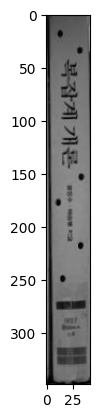

Best SSD val: 0.09677071124315262
Not enough matches: 37/90. SSD: 0.09677071124315262.
Best SSD val: 0.11081673204898834
New match found with 98/90 good matches. SSD: 0.11081673204898834.
Best SSD val: 0.14343398809432983
Not enough matches: 26/90. SSD: 0.14343398809432983.
Best SSD val: 0.14676393568515778
Not enough matches: 34/90. SSD: 0.14676393568515778.
Best SSD val: 0.1696341633796692
Not enough matches: 18/90. SSD: 0.1696341633796692.
Best SSD val: 0.1739460676908493
Not enough matches: 11/90. SSD: 0.1739460676908493.
Best SSD val: 0.1824760138988495
Not enough matches: 5/90. SSD: 0.1824760138988495.
Best SSD val: 0.18962334096431732
Not enough matches: 28/90. SSD: 0.18962334096431732.
Best SSD val: 0.1994892805814743
Not enough matches: 1/90. SSD: 0.1994892805814743.
Best SSD val: 0.2003781795501709
Not enough matches: 15/90. SSD: 0.2003781795501709.
Best SSD val: 0.20088240504264832
Not enough matches: 3/90. SSD: 0.20088240504264832.
Best SSD val: 0.20205672085285187
Not enou

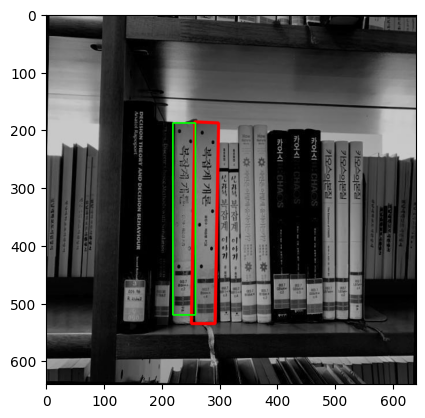

-------- Processing model 12 --------
Homography computed successfully


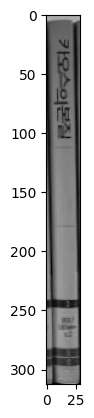

Best SSD val: 0.1079195961356163
Not enough matches: 22/47. SSD: 0.1079195961356163.
Best SSD val: 0.12385835498571396
New match found with 70/47 good matches. SSD: 0.12385835498571396.
Best SSD val: 0.12418744713068008
Not enough matches: 20/47. SSD: 0.12418744713068008.
Best SSD val: 0.1378108114004135
Not enough matches: 20/47. SSD: 0.1378108114004135.
Best SSD val: 0.1564745306968689
Not enough matches: 18/47. SSD: 0.1564745306968689.
Best SSD val: 0.17061127722263336
New match found with 75/47 good matches. SSD: 0.17061127722263336.
Best SSD val: 0.17538516223430634
Not enough matches: 23/47. SSD: 0.17538516223430634.
Best SSD val: 0.19217723608016968
Not enough matches: 5/47. SSD: 0.19217723608016968.
Best SSD val: 0.20477092266082764
Not enough matches: 1/47. SSD: 0.20477092266082764.
Best SSD val: 0.20640408992767334
Not enough matches: 6/47. SSD: 0.20640408992767334.
Best SSD val: 0.2181852161884308
Not enough matches: 1/47. SSD: 0.2181852161884308.
Best SSD val: 0.22841554880

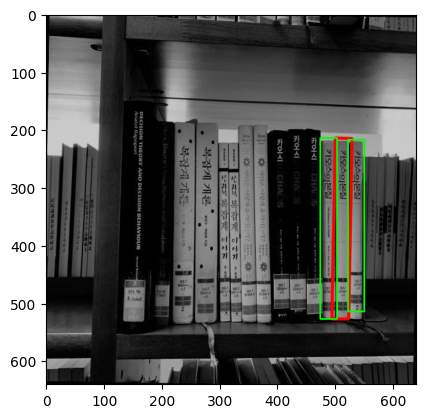

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 17 ---------------------------------
-------- Processing model 0 --------
Homography could not

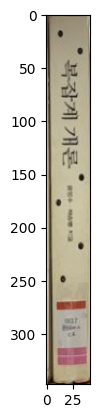

Best SSD val: 0.07048429548740387
Not enough matches: 33/90. SSD: 0.07048429548740387.
Best SSD val: 0.08987309038639069
New match found with 97/90 good matches. SSD: 0.08987309038639069.
Best SSD val: 0.09266407787799835
Not enough matches: 47/90. SSD: 0.09266407787799835.
Best SSD val: 0.09663157165050507
Not enough matches: 29/90. SSD: 0.09663157165050507.
Best SSD val: 0.10707908123731613
Not enough matches: 29/90. SSD: 0.10707908123731613.
Best SSD val: 0.11359847337007523
Not enough matches: 15/90. SSD: 0.11359847337007523.
Best SSD val: 0.11361686140298843
Not enough matches: 14/90. SSD: 0.11361686140298843.
Best SSD val: 0.12614533305168152
Not enough matches: 32/90. SSD: 0.12614533305168152.
Best SSD val: 0.12983381748199463
Not enough matches: 18/90. SSD: 0.12983381748199463.
Best SSD val: 0.1309935301542282
Not enough matches: 13/90. SSD: 0.1309935301542282.
Best SSD val: 0.13244451582431793
Not enough matches: 12/90. SSD: 0.13244451582431793.
Best SSD val: 0.132347598671913

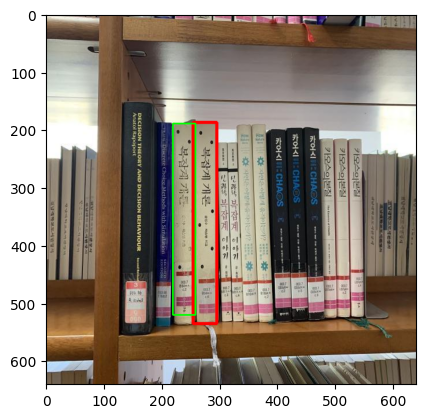

-------- Processing model 12 --------
Homography computed successfully


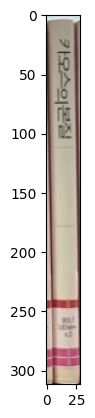

Best SSD val: 0.06443658471107483
New match found with 99/47 good matches. SSD: 0.06443658471107483.
Best SSD val: 0.06709744036197662
Not enough matches: 21/47. SSD: 0.06709744036197662.
Best SSD val: 0.07308325916528702
Not enough matches: 14/47. SSD: 0.07308325916528702.
Best SSD val: 0.08240076154470444
Not enough matches: 18/47. SSD: 0.08240076154470444.
Best SSD val: 0.08676609396934509
Not enough matches: 19/47. SSD: 0.08676609396934509.
Best SSD val: 0.1032027080655098
Not enough matches: 13/47. SSD: 0.1032027080655098.
Best SSD val: 0.10667866468429565
New match found with 76/47 good matches. SSD: 0.10667866468429565.
Best SSD val: 0.11777909845113754
Not enough matches: 22/47. SSD: 0.11777909845113754.
Best SSD val: 0.13441723585128784
Not enough matches: 3/47. SSD: 0.13441723585128784.
Best SSD val: 0.1370639055967331
Not enough matches: 15/47. SSD: 0.1370639055967331.
Best SSD val: 0.14221659302711487
Not enough matches: 13/47. SSD: 0.14221659302711487.
Best SSD val: 0.1487

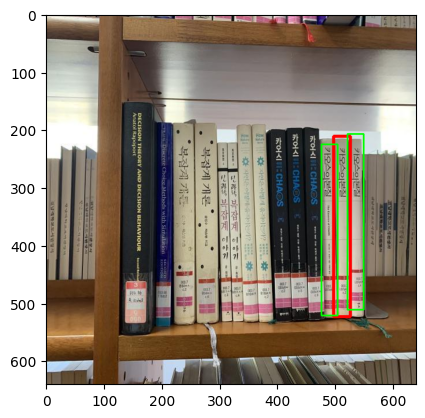

-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography could not be computed. No instances detected.
--------------------------------- Processing scene 18 ---------------------------------
-------- Processing model 0 --------
Homography could not

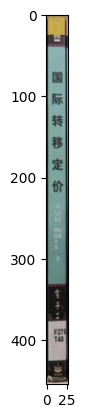

Best SSD val: 0.07606957852840424
New match found with 226/91 good matches. SSD: 0.07606957852840424.
Best SSD val: 0.0808371901512146
New match found with 222/91 good matches. SSD: 0.0808371901512146.
Best SSD val: 0.1482791006565094
Not enough matches: 36/91. SSD: 0.1482791006565094.
Best SSD val: 0.15333589911460876
Not enough matches: 41/91. SSD: 0.15333589911460876.
Best SSD val: 0.15659376978874207
Not enough matches: 28/91. SSD: 0.15659376978874207.
Best SSD val: 0.15955722332000732
Not enough matches: 43/91. SSD: 0.15955722332000732.
Best SSD val: 0.16901029646396637
Not enough matches: 30/91. SSD: 0.16901029646396637.
Best SSD val: 0.18317580223083496
Not enough matches: 42/91. SSD: 0.18317580223083496.
Best SSD val: 0.19252651929855347
Not enough matches: 41/91. SSD: 0.19252651929855347.
Best SSD val: 0.1927301287651062
Not enough matches: 34/91. SSD: 0.1927301287651062.
Best SSD val: 0.212758868932724
Not enough matches: 7/91. SSD: 0.212758868932724.
Best SSD val: 0.22072830

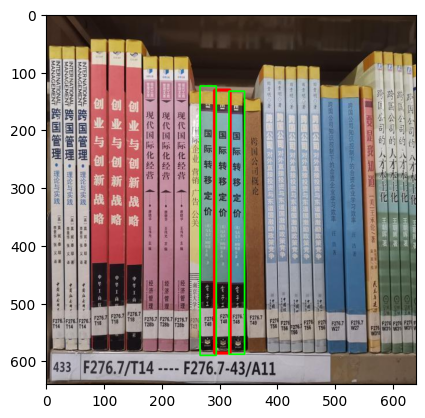

-------- Processing model 9 --------
Homography computed successfully


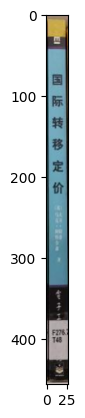

Best SSD val: 0.07786279916763306
New match found with 234/97 good matches. SSD: 0.07786279916763306.
Best SSD val: 0.08481577783823013
New match found with 231/97 good matches. SSD: 0.08481577783823013.
Best SSD val: 0.1360350102186203
Not enough matches: 42/97. SSD: 0.1360350102186203.
Best SSD val: 0.14378538727760315
Not enough matches: 46/97. SSD: 0.14378538727760315.
Best SSD val: 0.1474919468164444
Not enough matches: 41/97. SSD: 0.1474919468164444.
Best SSD val: 0.1495264768600464
Not enough matches: 34/97. SSD: 0.1495264768600464.
Best SSD val: 0.17124876379966736
Not enough matches: 41/97. SSD: 0.17124876379966736.
Best SSD val: 0.20096492767333984
Not enough matches: 26/97. SSD: 0.20096492767333984.
Best SSD val: 0.20178957283496857
Not enough matches: 43/97. SSD: 0.20178957283496857.
Best SSD val: 0.20477931201457977
Not enough matches: 43/97. SSD: 0.20477931201457977.
Best SSD val: 0.20651893317699432
Not enough matches: 10/97. SSD: 0.20651893317699432.
Best SSD val: 0.210

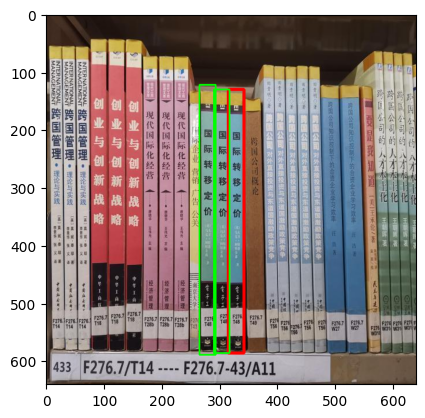

-------- Processing model 10 --------
Homography computed successfully


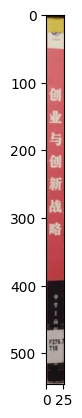

Best SSD val: 0.03531787544488907
New match found with 230/86 good matches. SSD: 0.03531787544488907.
Best SSD val: 0.050013281404972076
New match found with 223/86 good matches. SSD: 0.050013281404972076.
Best SSD val: 0.17951177060604095
Not enough matches: 41/86. SSD: 0.17951177060604095.
Best SSD val: 0.1897285431623459
Not enough matches: 51/86. SSD: 0.1897285431623459.
Best SSD val: 0.19213390350341797
Not enough matches: 18/86. SSD: 0.19213390350341797.
Best SSD val: 0.1992689073085785
Not enough matches: 56/86. SSD: 0.1992689073085785.
Best SSD val: 0.20373450219631195
Not enough matches: 48/86. SSD: 0.20373450219631195.
Best SSD val: 0.20866814255714417
Not enough matches: 38/86. SSD: 0.20866814255714417.
Best SSD val: 0.20934055745601654
Not enough matches: 33/86. SSD: 0.20934055745601654.
Best SSD val: 0.21741721034049988
Not enough matches: 26/86. SSD: 0.21741721034049988.
Best SSD val: 0.23703432083129883
Not enough matches: 18/86. SSD: 0.23703432083129883.
Best SSD val: 0

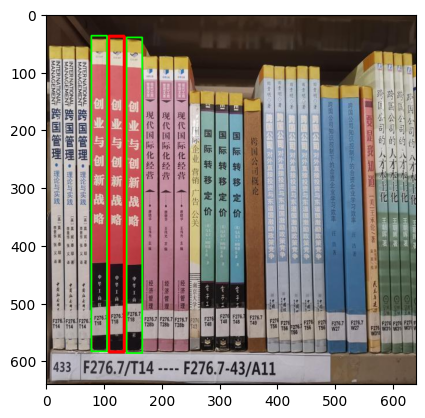

-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography could not be computed. No instances detected.
-------- Processing model 19 --------
Homography could not be computed. No instances detected.
-------- Processing model 20 --------
Homography could not be computed. No instances detected.
-------- Processing model 21 --------
Homography c

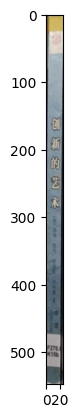

Best SSD val: 0.04050680994987488
New match found with 179/95 good matches. SSD: 0.04050680994987488.
Best SSD val: 0.0646834522485733
New match found with 178/95 good matches. SSD: 0.0646834522485733.
Best SSD val: 0.11272726207971573
Not enough matches: 34/95. SSD: 0.11272726207971573.
Best SSD val: 0.11498993635177612
Not enough matches: 36/95. SSD: 0.11498993635177612.
Best SSD val: 0.11776970326900482
Not enough matches: 28/95. SSD: 0.11776970326900482.
Best SSD val: 0.11824079602956772
Not enough matches: 25/95. SSD: 0.11824079602956772.
Best SSD val: 0.12839750945568085
Not enough matches: 29/95. SSD: 0.12839750945568085.
Best SSD val: 0.1303703784942627
Not enough matches: 26/95. SSD: 0.1303703784942627.
Best SSD val: 0.13037154078483582
Not enough matches: 47/95. SSD: 0.13037154078483582.
Best SSD val: 0.13052937388420105
Not enough matches: 29/95. SSD: 0.13052937388420105.
Best SSD val: 0.1326809525489807
Not enough matches: 27/95. SSD: 0.1326809525489807.
Best SSD val: 0.124

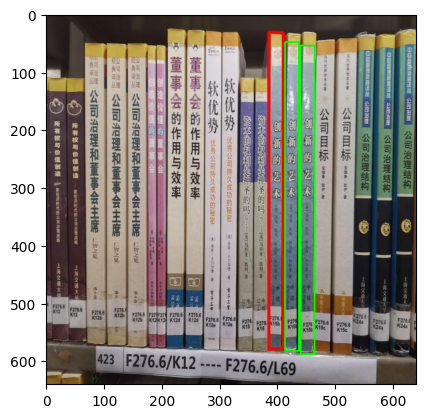

-------- Processing model 7 --------
Homography computed successfully


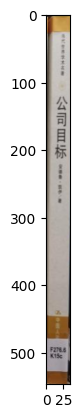

Best SSD val: 0.04258568957448006
New match found with 218/71 good matches. SSD: 0.04258568957448006.
Best SSD val: 0.08161940425634384
Not enough matches: 39/71. SSD: 0.08161940425634384.
Best SSD val: 0.09563148766756058
Not enough matches: 52/71. SSD: 0.09563148766756058.
Best SSD val: 0.09788181632757187
Not enough matches: 51/71. SSD: 0.09788181632757187.
Best SSD val: 0.10156907141208649
New match found with 71/71 good matches. SSD: 0.10156907141208649.
Best SSD val: 0.1116189956665039
Not enough matches: 66/71. SSD: 0.1116189956665039.
Best SSD val: 0.11448231339454651
Not enough matches: 67/71. SSD: 0.11448231339454651.
Best SSD val: 0.10518114268779755
Not enough matches: 68/71. SSD: 0.10518114268779755.
Best SSD val: 0.12478785216808319
Not enough matches: 46/71. SSD: 0.12478785216808319.
Best SSD val: 0.12990067899227142
Not enough matches: 30/71. SSD: 0.12990067899227142.
Best SSD val: 0.13659177720546722
Not enough matches: 48/71. SSD: 0.13659177720546722.
Best SSD val: 0.

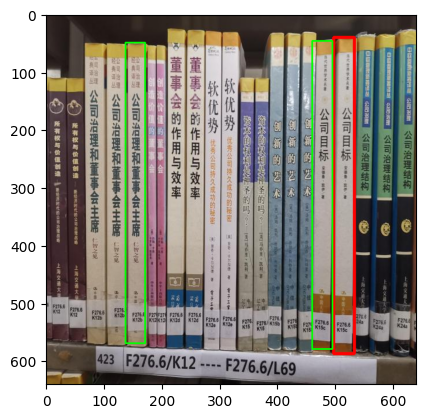

-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could not be computed. No instances detected.
-------- Processing model 17 --------
Homography could not be computed. No instances detected.
-------- Processing model 18 --------
Homography cou

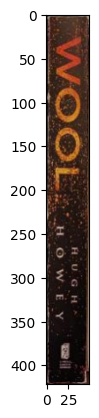

Best SSD val: 0.3953153192996979
Value 0.3953153192996979 above high threshold 0.27. No match found.
No match found during template matching on instance 2. Matching value: 0.3953153192996979/0.03.
Total instances detected: 1


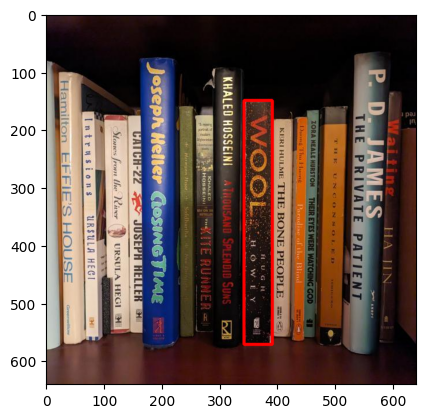

-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could not be computed. No instances detected.
-------- Processing model 16 --------
Homography could

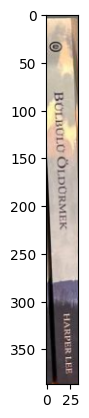

Best SSD val: 0.07933753728866577
New match found with 252/100 good matches. SSD: 0.07933753728866577.
Best SSD val: 0.08627145737409592
Not enough matches: 46/100. SSD: 0.08627145737409592.
Best SSD val: 0.10166177153587341
Not enough matches: 39/100. SSD: 0.10166177153587341.
Best SSD val: 0.11760822683572769
Not enough matches: 35/100. SSD: 0.11760822683572769.
Best SSD val: 0.12062330543994904
Not enough matches: 22/100. SSD: 0.12062330543994904.
Best SSD val: 0.13130070269107819
Not enough matches: 33/100. SSD: 0.13130070269107819.
Best SSD val: 0.15083494782447815
Not enough matches: 25/100. SSD: 0.15083494782447815.
Best SSD val: 0.16026310622692108
Not enough matches: 46/100. SSD: 0.16026310622692108.
Best SSD val: 0.16512131690979004
Not enough matches: 29/100. SSD: 0.16512131690979004.
Best SSD val: 0.18724079430103302
Not enough matches: 29/100. SSD: 0.18724079430103302.
Best SSD val: 0.1975088268518448
Not enough matches: 7/100. SSD: 0.1975088268518448.
Best SSD val: 0.1996

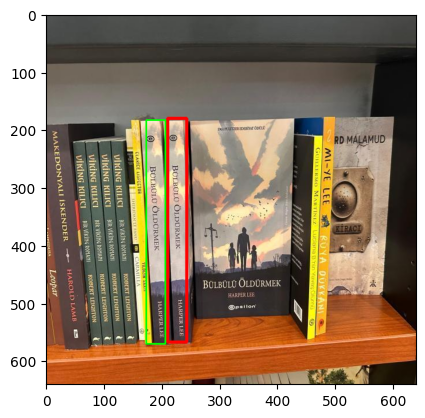

-------- Processing model 1 --------
Homography could not be computed. No instances detected.
-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography computed successfully


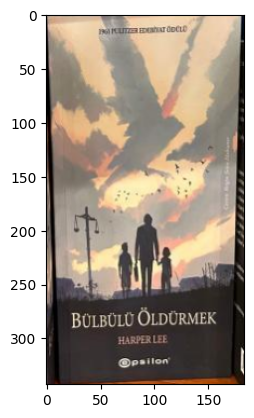

Best SSD val: 0.21283258497714996
Not enough matches: 214/329. SSD: 0.21283258497714996.
Best SSD val: 0.21321159601211548
Not enough matches: 232/329. SSD: 0.21321159601211548.
Best SSD val: 0.21457761526107788
Not enough matches: 213/329. SSD: 0.21457761526107788.
Best SSD val: 0.21317100524902344
Not enough matches: 225/329. SSD: 0.21317100524902344.
Best SSD val: 0.21235890686511993
Not enough matches: 222/329. SSD: 0.21235890686511993.
Best SSD val: 0.21461617946624756
Not enough matches: 220/329. SSD: 0.21461617946624756.
Best SSD val: 0.21518565714359283
Not enough matches: 230/329. SSD: 0.21518565714359283.
Best SSD val: 0.2134740799665451
Not enough matches: 222/329. SSD: 0.2134740799665451.
Best SSD val: 0.21297840774059296
Not enough matches: 218/329. SSD: 0.21297840774059296.
Best SSD val: 0.21400724351406097
Not enough matches: 225/329. SSD: 0.21400724351406097.
Best SSD val: 0.21116772294044495
Not enough matches: 216/329. SSD: 0.21116772294044495.
Best SSD val: 0.2131063

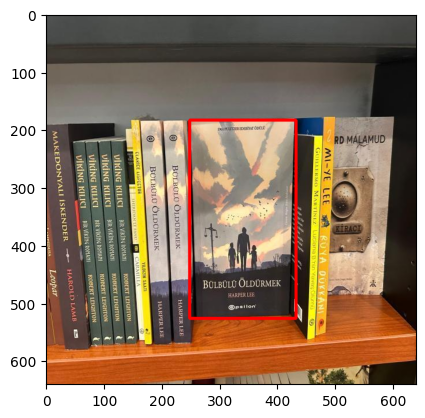

-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could not be computed. No instances detected.
-------- Processing model 15 --------
Homography could 

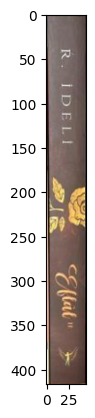

Best SSD val: 0.10215605050325394
New match found with 157/111 good matches. SSD: 0.10215605050325394.
Best SSD val: 0.1567709892988205
New match found with 119/111 good matches. SSD: 0.1567709892988205.
Best SSD val: 0.17923516035079956
Not enough matches: 20/111. SSD: 0.17923516035079956.
Best SSD val: 0.1797635704278946
Not enough matches: 21/111. SSD: 0.1797635704278946.
Best SSD val: 0.18231366574764252
New match found with 122/111 good matches. SSD: 0.18231366574764252.
Best SSD val: 0.18269719183444977
Not enough matches: 19/111. SSD: 0.18269719183444977.
Best SSD val: 0.17817983031272888
Not enough matches: 19/111. SSD: 0.17817983031272888.
Best SSD val: 0.18007539212703705
Not enough matches: 22/111. SSD: 0.18007539212703705.
Best SSD val: 0.18172137439250946
Not enough matches: 25/111. SSD: 0.18172137439250946.
Best SSD val: 0.1791771650314331
Not enough matches: 21/111. SSD: 0.1791771650314331.
Best SSD val: 0.1763693243265152
Not enough matches: 29/111. SSD: 0.1763693243265

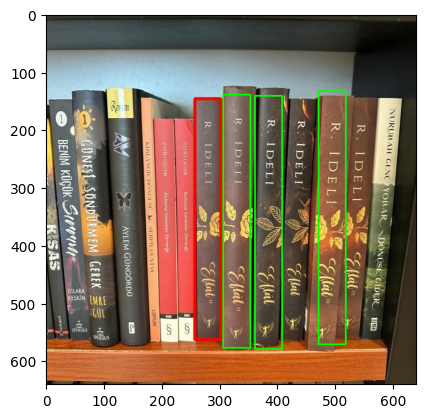

-------- Processing model 3 --------
Homography computed successfully


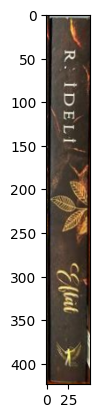

Best SSD val: 0.26652976870536804
New match found with 129/115 good matches. SSD: 0.26652976870536804.
Best SSD val: 0.3152141571044922
Value 0.3152141571044922 above high threshold 0.27. No match found.
No match found during template matching on instance 3. Matching value: 0.3152141571044922/0.03.
Total instances detected: 2


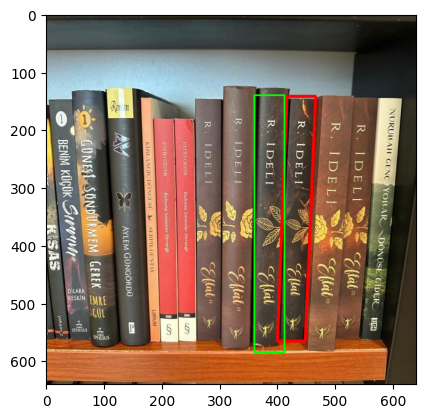

-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not be computed. No instances detected.
-------- Processing model 13 --------
Homography could not be computed. No instances detected.
-------- Processing model 14 --------
Homography could n

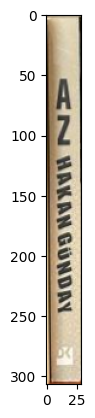

Best SSD val: 0.09916847199201584
New match found with 161/77 good matches. SSD: 0.09916847199201584.
Best SSD val: 0.14869290590286255
Not enough matches: 6/77. SSD: 0.14869290590286255.
Best SSD val: 0.1619335412979126
Not enough matches: 9/77. SSD: 0.1619335412979126.
Best SSD val: 0.1672661006450653
Not enough matches: 7/77. SSD: 0.1672661006450653.
Best SSD val: 0.17083559930324554
Not enough matches: 10/77. SSD: 0.17083559930324554.
Best SSD val: 0.1712750345468521
Not enough matches: 5/77. SSD: 0.1712750345468521.
Best SSD val: 0.16695287823677063
Not enough matches: 11/77. SSD: 0.16695287823677063.
Best SSD val: 0.1748349964618683
Not enough matches: 2/77. SSD: 0.1748349964618683.
Best SSD val: 0.17543071508407593
Not enough matches: 19/77. SSD: 0.17543071508407593.
Best SSD val: 0.17644451558589935
Not enough matches: 10/77. SSD: 0.17644451558589935.
Best SSD val: 0.17125998437404633
Not enough matches: 7/77. SSD: 0.17125998437404633.
Best SSD val: 0.16933366656303406
Not enou

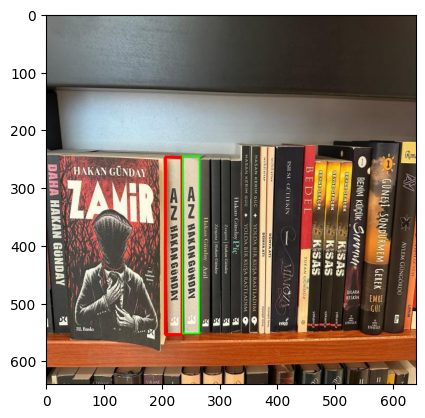

-------- Processing model 2 --------
Homography could not be computed. No instances detected.
-------- Processing model 3 --------
Homography could not be computed. No instances detected.
-------- Processing model 4 --------
Homography could not be computed. No instances detected.
-------- Processing model 5 --------
Homography could not be computed. No instances detected.
-------- Processing model 6 --------
Homography could not be computed. No instances detected.
-------- Processing model 7 --------
Homography could not be computed. No instances detected.
-------- Processing model 8 --------
Homography could not be computed. No instances detected.
-------- Processing model 9 --------
Homography could not be computed. No instances detected.
-------- Processing model 10 --------
Homography could not be computed. No instances detected.
-------- Processing model 11 --------
Homography could not be computed. No instances detected.
-------- Processing model 12 --------
Homography could not

In [37]:
grayscale = False
crosscheck = False
lowe_ratio = 0.75
min_match_pct = 0.075
#hyst_th = (0.465, 0.80)
hyst_th = (0.03, 0.27)

for i in range(0, 29):
     print(f"--------------------------------- Processing scene {i} ---------------------------------")
     scene_path = f'./dataset/scenes/scene_{i}.jpg'
     for j in range(0, 22):
          print(f"-------- Processing model {j} --------")

          model_path = f'./dataset/models/model_{j}.png'
          
          main(model_path, scene_path, 
               grayscale=grayscale, 
               hysteresys_th=hyst_th, 
               min_match_pct=min_match_pct,
               cross_check=crosscheck, 
               lowe_ratio=lowe_ratio, 
               method=cv2.RANSAC, 
               ransacReprojThreshold=5.0, 
               similarity_measure=cv2.TM_CCOEFF_NORMED)